# Notebook 6: Capstone. Choosing the Right Storage for a Real Product

## What this notebook is about, in one paragraph

You now know every storage place on the official page: memory, disk, disk plus terminal, store, Context Hub,
your own database, and the mail room that combines them. The hard part in real projects is **choosing**. This
notebook gives you **five simple questions** to ask, shows how to answer them for real products, and then builds a
complete assistant used by **several companies at once**, where we prove that each company only sees its own data.

## How to use this notebook

* Run the cells **from top to bottom**, one at a time (Shift + Enter).
* Before each code cell, read **what we are about to do** and **what to look for**.
* After each code cell, read **what just happened**.

---
# Part 1: Five questions to ask about every folder

Before writing any code, ask these five questions. Ask them **for each kind of file**, not once for the whole
agent, because different files usually get different answers.

| # | Question | If the answer is... | Use... |
|---|---|---|---|
| 1 | **How long must it be kept?** | Only during this conversation | memory (`StateBackend`) |
| | | Longer | a store, Context Hub, disk or your own database |
| 2 | **Who may see it?** | One user / one company / everyone | a drawer name with the user / company / nothing in it |
| 3 | **Where does it already live?** | In a folder on a computer | the disk (`FilesystemBackend`, locked) |
| | | In a database or online service | your own storage place (Notebook 5) |
| 4 | **Must the agent run programs?** | Yes, on my own trusted computer | disk + terminal (`LocalShellBackend`) with approval |
| | | Yes, for strangers or on a server | an isolated sandbox |
| 5 | **Who may change it?** | Nobody / only with approval / anyone | a permission rule: deny / ask a human / nothing |

When different files give different answers, combine them with the **mail room** (`CompositeBackend`).
The diagram below turns the questions into a path you can follow.

**Diagram: follow the questions to a storage place, then combine them in the mail room**

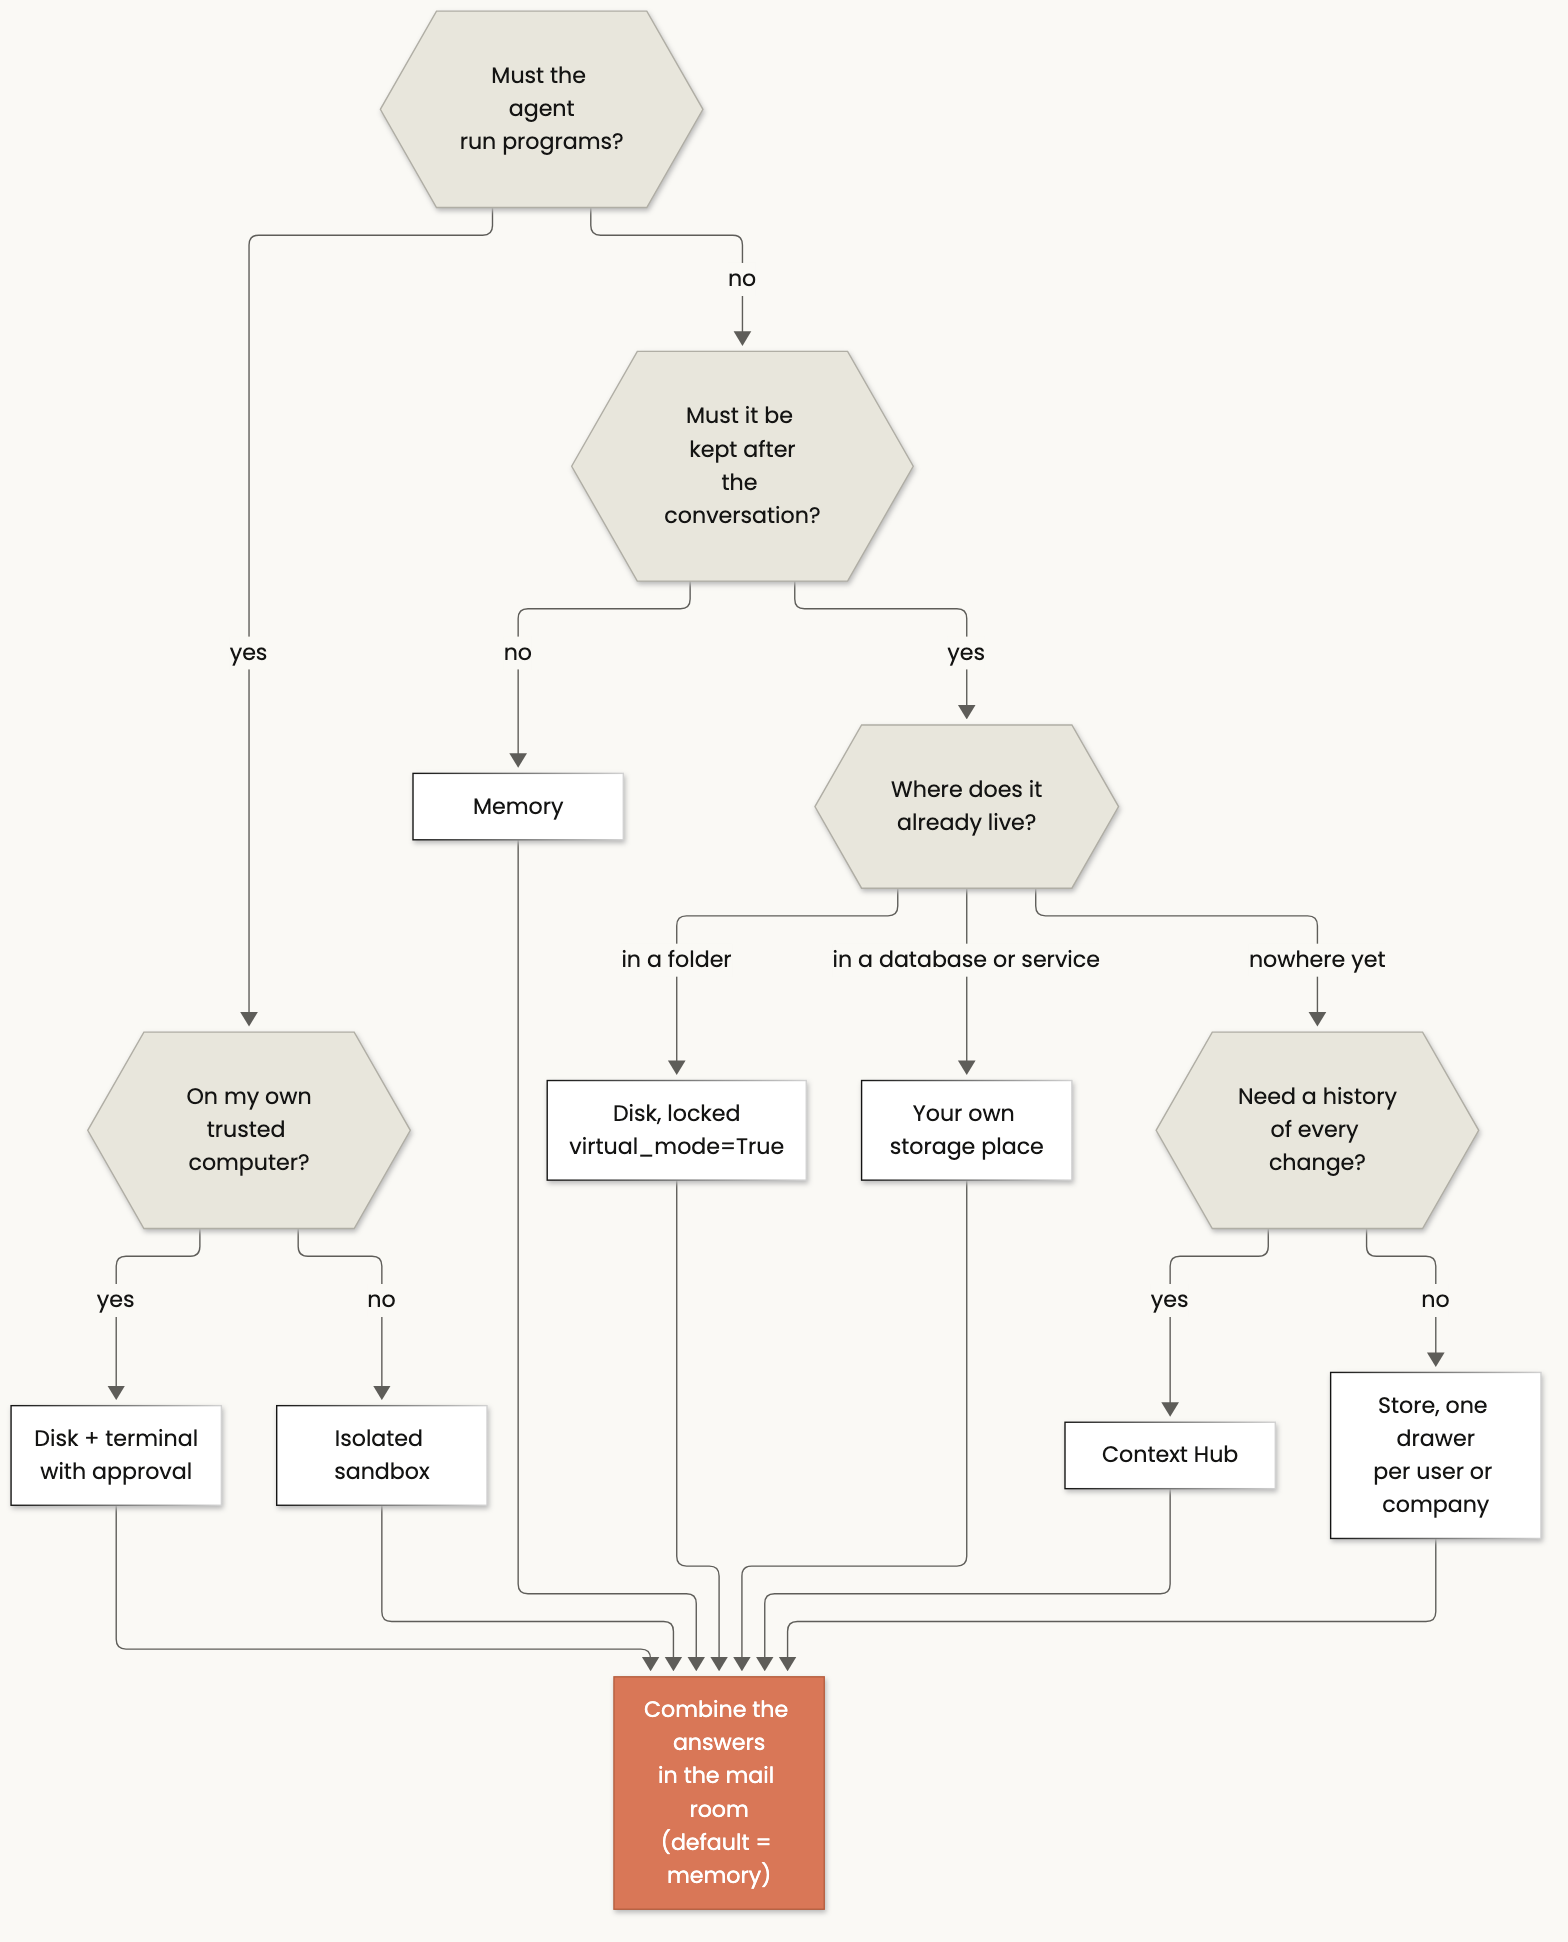

<details><summary>Mermaid source (also saved as diagrams/nb06v3_decision.mmd)</summary>

```mermaid
flowchart TD
    Q1{{"Must the agent<br/>run programs?"}} -->|"yes"| Q2{{"On my own<br/>trusted computer?"}}
    Q2 -->|"yes"| LS["Disk + terminal<br/>with approval"]
    Q2 -->|"no"| SB["Isolated sandbox"]
    Q1 -->|"no"| Q3{{"Must it be kept after<br/>the conversation?"}}
    Q3 -->|"no"| ST["Memory"]
    Q3 -->|"yes"| Q4{{"Where does it<br/>already live?"}}
    Q4 -->|"in a folder"| FS["Disk, locked<br/>virtual_mode=True"]
    Q4 -->|"in a database or service"| CU["Your own storage place"]
    Q4 -->|"nowhere yet"| Q5{{"Need a history<br/>of every change?"}}
    Q5 -->|"yes"| CH["Context Hub"]
    Q5 -->|"no"| SO["Store, one drawer<br/>per user or company"]
    LS --> CO["Combine the answers<br/>in the mail room<br/>(default = memory)"]
    SB --> CO
    ST --> CO
    FS --> CO
    CU --> CO
    CH --> CO
    SO --> CO
    class CO orange
    class Q1,Q2,Q3,Q4,Q5 soft

classDef orange fill:#D97757,stroke:#B65F3F,color:#FFFFFF
classDef green fill:#788C5D,stroke:#5F7048,color:#FFFFFF
classDef blue fill:#6A9BCC,stroke:#4F7FAE,color:#FFFFFF
classDef dark fill:#141413,stroke:#141413,color:#FAF9F5
classDef soft fill:#E8E6DC,stroke:#B0AEA5,color:#141413
classDef bad fill:#F7E3DA,stroke:#D97757,color:#141413

```

</details>

---
# Part 2: Twelve real products, one answer each

Try to answer each row yourself before reading the right column.

| # | Product | What to use | Why |
|---|---|---|---|
| 1 | A chat assistant on a website | memory | Each chat gets private scratch paper, nothing is kept, safe on a server |
| 2 | The same assistant, but it should remember the user | mail room: memory + `/memories/` in a store, one drawer per user | Keep only what must be kept |
| 3 | A coding assistant on a developer's laptop | disk + terminal, locked, with approval | It must edit files and run tests, on a trusted machine |
| 4 | An agent that updates documentation in a project | mail room: memory + `/workspace/` on disk | Real files, no terminal, scratch stays out of the project |
| 5 | A data assistant that runs code on files users upload | isolated sandbox | It runs code from strangers |
| 6 | A support assistant used by many companies | mail room: memory, per user store, per company store, read only policies | Companies must never see each other's data (built below) |
| 7 | A bot that answers from the company wiki | your own storage place for the wiki, writing denied | The data already lives in another service |
| 8 | Instructions and skills shared by many teams | Context Hub | History of every change, skills shared between agents |
| 9 | A research agent with helpers and huge web results | memory | Helpers share files, big results are parked and searched |
| 10 | An agent that looks at many screenshots | disk or sandbox + image offloading | Keeps the conversation small |
| 11 | An agent that edits a database of published articles | your own storage place + policy guard + approval | Checks in code and a human in the loop |
| 12 | A public demo anyone can type into | memory only, **never** disk or terminal | No way to reach the server's files |

---
# Part 3: The capstone. "Helix", a support assistant for many companies

**The product:** Helix is a support assistant sold to many companies. Today two companies use it:
**Acme** (support agents Sam and Ana) and **Globex** (support agent Lee).

**The requirements**, as a product manager would write them:

1. Companies must **never** see each other's data.
2. Each support agent has **private notes** that are kept across conversations.
3. Each company has **team notes** that all its agents can read and write.
4. Each company has **policies** the AI may read but **never change**.
5. There is a shared **product knowledge base** in a **database**. Every access is **logged**, and **secrets must
   never be saved** into it.
6. Scratch paper must **not** be kept.

### Answering the five questions, folder by folder

| Folder | Kept how long? | Who may see it? | Lives where already? | Who may change it? | Result |
|---|---|---|---|---|---|
| anything else | this conversation | this conversation | nowhere | the agent | memory (the default) |
| `/memories/` | forever | one support agent | nowhere | the agent | store, drawer `(company, agent, "memories")` |
| `/team/` | forever | one company | nowhere | the agent | store, drawer `(company, "team")` |
| `/policies/` | forever | one company | set by admins | nobody | store, drawer `(company, "policies")` + deny writing |
| `/kb/` | forever | everyone | a database | the agent, checked | database (Notebook 5) + policy guard |

**Diagram: the Helix design: who uses it, where each folder really goes**

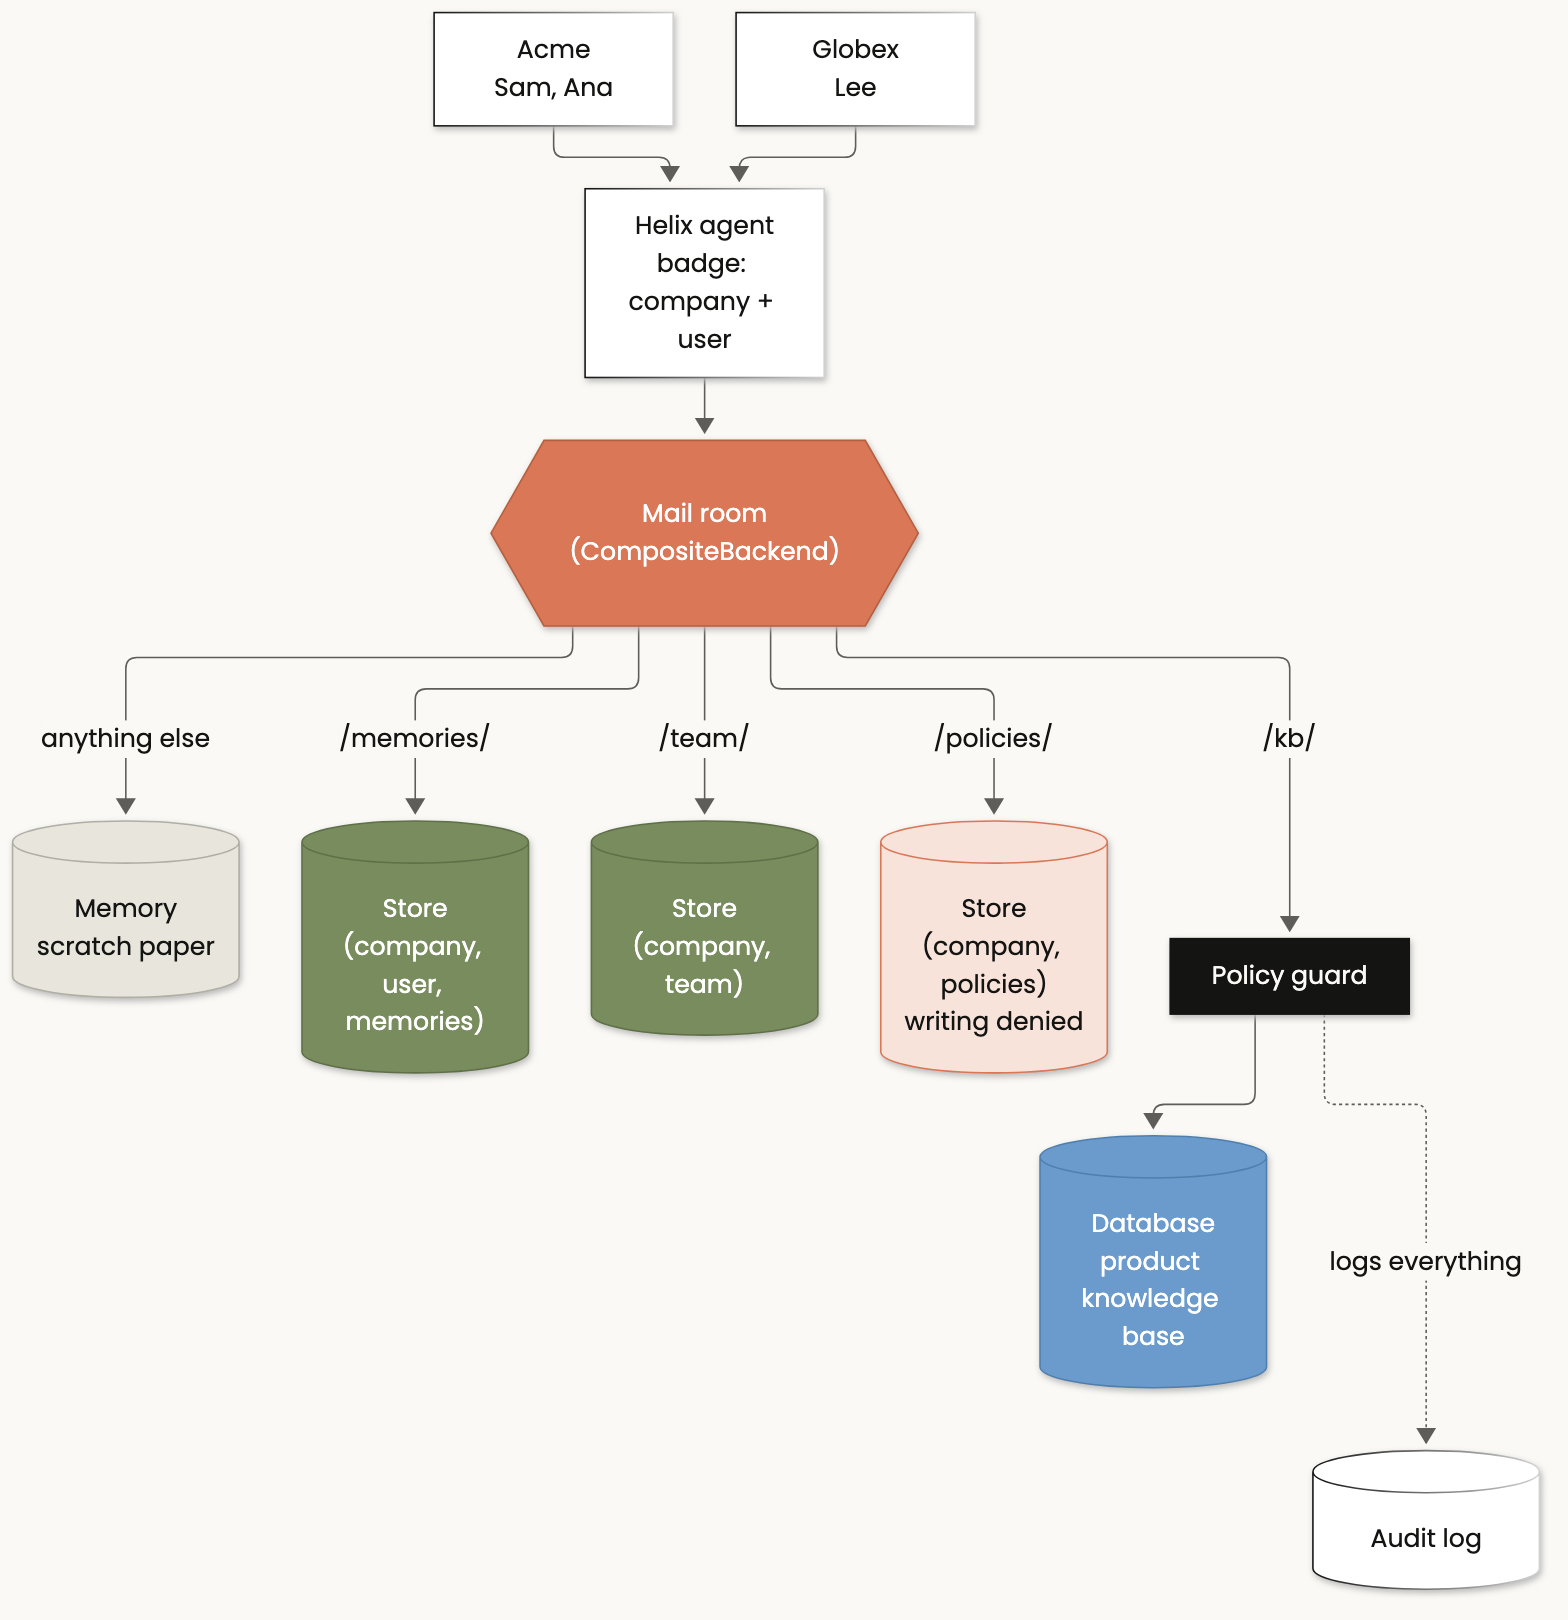

<details><summary>Mermaid source (also saved as diagrams/nb06v3_helix.mmd)</summary>

```mermaid
flowchart TB
    AC["Acme<br/>Sam, Ana"] --> H["Helix agent<br/>badge: company + user"]
    GX["Globex<br/>Lee"] --> H
    H --> CB{{"Mail room<br/>(CompositeBackend)"}}
    CB -->|"anything else"| S[("Memory<br/>scratch paper")]
    CB -->|"/memories/"| M[("Store<br/>(company, user, memories)")]
    CB -->|"/team/"| T[("Store<br/>(company, team)")]
    CB -->|"/policies/"| P[("Store<br/>(company, policies)<br/>writing denied")]
    CB -->|"/kb/"| K["Policy guard"]
    K --> DB[("Database<br/>product knowledge base")]
    K -. "logs everything" .-> LOG[("Audit log")]
    class CB orange
    class S soft
    class M,T green
    class P bad
    class K dark
    class DB blue

classDef orange fill:#D97757,stroke:#B65F3F,color:#FFFFFF
classDef green fill:#788C5D,stroke:#5F7048,color:#FFFFFF
classDef blue fill:#6A9BCC,stroke:#4F7FAE,color:#FFFFFF
classDef dark fill:#141413,stroke:#141413,color:#FAF9F5
classDef soft fill:#E8E6DC,stroke:#B0AEA5,color:#141413
classDef bad fill:#F7E3DA,stroke:#D97757,color:#141413

```

</details>

### Step 1: create the data that already exists

In a real company, the policies and the knowledge base exist before the assistant. We create them here:

* **Acme's policy:** support may approve refunds up to 500 USD.
* **Globex's policy:** support may **not** approve refunds at all.
* **The knowledge base:** two help articles, in a database file.

Notice both companies' policy files have **the same name**, `/refunds.md`, in **different drawers**.

In [1]:
# Load the class helpers (the reload line makes sure we always use the latest version)
import importlib, course_utils
importlib.reload(course_utils)

import custom_backends
importlib.reload(custom_backends)
from custom_backends import SQLiteBackend, AuditedPolicyBackend
from course_utils import MODEL, show_trace, show_store, where_did_files_go
from deepagents import create_deep_agent, FilesystemPermission
from deepagents.backends import CompositeBackend, StateBackend, StoreBackend
from langgraph.store.memory import InMemoryStore
from langgraph.checkpoint.memory import InMemorySaver
from dataclasses import dataclass
from pathlib import Path
import shutil

LAB = Path.cwd() / "playground" / "helix"
shutil.rmtree(LAB, ignore_errors=True)
LAB.mkdir(parents=True)

store = InMemoryStore()       # in production: a real database store, or nothing on LangSmith Deployment

def put_in_drawer(drawer, file_name, text):
    StoreBackend(store=store, namespace=lambda _rt: drawer).write(file_name, text)

put_in_drawer(("acme", "policies"), "/refunds.md", "Acme policy: refunds up to 500 USD can be approved by support. Above that, escalate to finance.")
put_in_drawer(("globex", "policies"), "/refunds.md", "Globex policy: support may NOT approve refunds. Always escalate to billing@globex.example.")

product_kb = SQLiteBackend(str(LAB / "product_kb.sqlite"))
product_kb.write("/exports.md", "# Data export\nUsers can export data as CSV or JSON from Settings > Data.\n")
product_kb.write("/sso.md", "# SSO\nSAML SSO with Okta and Azure AD on the Enterprise plan.\n")
guarded_kb = AuditedPolicyBackend(product_kb, max_writes=10)

print("Knowledge base database on your Mac:", LAB / "product_kb.sqlite")
print()
show_store(store)

Knowledge base database on your Mac: /Users/datasense/Desktop/deepagents/notebooks/playground/helix/product_kb.sqlite

The store holds 2 file(s):
  drawer ('acme', 'policies')  file /refunds.md
      content: Acme policy: refunds up to 500 USD can be approved by support. Above that, escalate to fin ...
  drawer ('globex', 'policies')  file /refunds.md
      content: Globex policy: support may NOT approve refunds. Always escalate to billing@globex.example.


### Step 2: build Helix from the design table

Each line of `routes` is one row of the design table. The "visitor badge" `HelixContext` tells Helix **which
company** and **which support agent** is talking. The drawer names are built from that badge.

In [2]:
@dataclass
class HelixContext:          # the badge: which company and which support agent
    org_id: str
    user_id: str

helix = create_deep_agent(
    model=MODEL,
    backend=CompositeBackend(
        default=StateBackend(),                                                                         # scratch paper
        routes={
            "/memories/": StoreBackend(namespace=lambda rt: (rt.context.org_id, rt.context.user_id, "memories")),
            "/team/":     StoreBackend(namespace=lambda rt: (rt.context.org_id, "team")),
            "/policies/": StoreBackend(namespace=lambda rt: (rt.context.org_id, "policies")),
            "/kb/":       guarded_kb,                                                                   # database + guard
        },
    ),
    store=store,
    checkpointer=InMemorySaver(),
    context_schema=HelixContext,
    permissions=[FilesystemPermission(operations=["write"], paths=["/policies/**"], mode="deny")],     # policies are read only
    system_prompt=(
        "You are Helix, a support assistant. Folders:\n"
        "* /policies/ company policies (read only, always check before promising anything)\n"
        "* /kb/ product knowledge base\n"
        "* /team/ shared notes for this company's support team\n"
        "* /memories/ private notes for the current support agent\n"
        "* anything else is temporary scratch space\n"
        "Read /memories/ and /team/ at the start of every conversation. "
        "Never say you saved something unless write_file succeeded. Be concise."
    ),
)

def ask(company, person, conversation, text):
    """Send one message to Helix as a given support agent of a given company."""
    return helix.invoke(
        {"messages": [{"role": "user", "content": text}]},
        config={"configurable": {"thread_id": f"{company}-{conversation}"}},
        context=HelixContext(org_id=company, user_id=person),
    )

print("Helix is ready.")

Helix is ready.


### Step 3: the same question from two companies

Sam (Acme) and Lee (Globex) ask **exactly the same question**.

**What to look for:** both agents open a file called `/policies/refunds.md`, but they should get **different
text**, and so give **opposite answers**.

In [3]:
print("SAM FROM ACME ASKS:")
show_trace(ask("acme", "sam", "c1", "A customer wants a 300 USD refund. Can I approve it?"))
print()
print("LEE FROM GLOBEX ASKS:")
show_trace(ask("globex", "lee", "c1", "A customer wants a 300 USD refund. Can I approve it?"))

SAM FROM ACME ASKS:


WHAT THE AGENT DID, STEP BY STEP
Step 1. The agent LOOKED INSIDE the folder /memories
         It got back: No files found
Step 2. The agent LOOKED INSIDE the folder /team
         It got back: No files found
Step 3. The agent LOOKED INSIDE the folder /policies
         It got back: ['/policies/refunds.md']
Step 4. The agent OPENED and read the file /policies/refunds.md
         It got back: (lines 1 to 1 of 1) Acme policy: refunds up to 500 USD can be approved by support. Above that, escalate to finance.
THE AGENT'S REPLY TO YOU:
Yes - you can approve a 300 USD refund. Company policy allows support to approve refunds up to 500 USD.

Note: file names in the steps above (starting with /) are the AGENT'S names for files,
not places on your Mac. See 'WHERE DID THE FILES GO?' for where they really are.

LEE FROM GLOBEX ASKS:


WHAT THE AGENT DID, STEP BY STEP
Step 1. The agent LOOKED INSIDE the folder /memories
         It got back: No files found
Step 2. The agent LOOKED INSIDE the folder /team
         It got back: No files found
Step 3. The agent LOOKED INSIDE the folder /policies
         It got back: ['/policies/refunds.md']
Step 4. The agent OPENED and read the file /policies/refunds.md
         It got back: (lines 1 to 1 of 1) Globex policy: support may NOT approve refunds. Always escalate to billing@globex.example.
THE AGENT'S REPLY TO YOU:
No - support may not approve refunds. Please escalate the request to billing@globex.example.

Note: file names in the steps above (starting with /) are the AGENT'S names for files,
not places on your Mac. See 'WHERE DID THE FILES GO?' for where they really are.


### What just happened

Same file name `/policies/refunds.md`, two different files, picked by the drawer name built from the badge.
Acme's answer is "yes", Globex's is "no, escalate". The AI never had to remember which company it works for:
**the separation lives in the storage, not in the AI's instructions.**

### Step 4: private notes versus team notes

Sam saves one note **only for himself** and one note **for his whole team**.
**What to look for:** two files saved, in **two different drawers**.

In [4]:
sam_run = ask("acme", "sam", "c2",
    "Save for me only (in my private memories): I prefer short replies. "
    "Save for the whole team (in team notes): customer Initech is on a custom 60 day refund window.")
show_trace(sam_run)
print()
where_did_files_go(sam_run, label="nb06_sam_notes", store_folders={
    "/memories/": (store, ("acme", "sam", "memories")),
    "/team/": (store, ("acme", "team")),
})

WHAT THE AGENT DID, STEP BY STEP
Step 1. The agent LOOKED INSIDE the folder /memories
         It got back: No files found
Step 2. The agent LOOKED INSIDE the folder /team
         It got back: No files found
Step 3. The agent tried to open the file /memories
         Nothing exists under that name yet, so there was nothing to read.
Step 4. The agent tried to open the file /team
         Nothing exists under that name yet, so there was nothing to read.
Step 5. The agent SEARCHED for files named *
         It got back: ['/kb/exports.md', '/kb/sso.md', '/policies/refunds.md']
Step 6. The agent SEARCHED for files named *
         It got back: ['/kb/exports.md', '/kb/sso.md', '/policies/refunds.md']
Step 7. The agent OPENED and read the file /policies/refunds.md
         It got back: (lines 1 to 1 of 1) Acme policy: refunds up to 500 USD can be approved by support. Above that, escalate to finance.
Step 8. The agent CREATED (or replaced) the file /memories/agent_notes.md
         It got bac

Now **Ana**, Sam's colleague at Acme, opens a **new conversation**.

**What to look for:** Ana should see the **team note** about Initech, but **not** Sam's private preference.

In [5]:
show_trace(ask("acme", "ana", "c3", "Anything special about Initech refunds? Also, do you know my reply preference?"))

WHAT THE AGENT DID, STEP BY STEP
Step 1. The agent LOOKED INSIDE the folder /memories
         It got back: No files found
Step 2. The agent LOOKED INSIDE the folder /team
         It got back: ['/team/shared_notes.md']
Step 3. The agent LOOKED INSIDE the folder /policies
         It got back: ['/policies/refunds.md']
Step 4. The agent OPENED and read the file /team/shared_notes.md
         It got back: (lines 1 to 1 of 1) Customer Initech is on a custom 60 day refund window.
Step 5. The agent OPENED and read the file /policies/refunds.md
         It got back: (lines 1 to 1 of 1) Acme policy: refunds up to 500 USD can be approved by support. Above that, escalate to finance.
THE AGENT'S REPLY TO YOU:
Yes - Initech has a custom 60-day refund window.

I don’t see any saved note about your reply preference, so I don’t know it yet. If you want, tell me your preference and I’ll follow it.

Note: file names in the steps above (starting with /) are the AGENT'S names for files,
not places on yo

### What just happened

Ana found the Initech team note (drawer `('acme', 'team')`) but no preference of her own
(her private drawer `('acme', 'ana', 'memories')` is empty). Sam's private note stayed private.

> **Lesson from preparing this class:** in an early run, the user wrote "Note for me..." and the AI replied
> "Noted" **without saving anything**. The next conversation knew nothing. Always check the steps, not just the
> reply. We fixed it with clearer wording and the instruction "never say you saved something unless it worked".

### Step 5: the safety rules under pressure

Sam asks Helix to do two forbidden things at once: **change a policy**, and **save a real looking API key** into
the shared knowledge base.

**What to look for:** both steps should say **NOT DONE**, for two different reasons.

In [6]:
show_trace(ask("acme", "sam", "c4",
    "Change /policies/refunds.md so support can approve up to 5000 USD. Also save this to the KB at /kb/acme-debug.md: "
    "'customer key sk-LIVE1234567890abcdefXYZ0001 fails on export'."))

WHAT THE AGENT DID, STEP BY STEP
Step 1. The agent tried to open the file /memories/README.md
         Nothing exists under that name yet, so there was nothing to read.
Step 2. The agent tried to open the file /team/README.md
         Nothing exists under that name yet, so there was nothing to read.
Step 3. The agent OPENED and read the file /policies/refunds.md
         It got back: (lines 1 to 1 of 1) Acme policy: refunds up to 500 USD can be approved by support. Above that, escalate to finance.
Step 4. The agent TRIED to create the file /policies/refunds.md
         NOT DONE. Reason: Error: permission denied for write on /policies/refunds.md
Step 5. The agent TRIED to create the file /kb/acme-debug.md
         NOT DONE. Reason: Blocked: content looks like a secret or credential. Never store secrets in files.
THE AGENT'S REPLY TO YOU:
I couldn’t make either change.

- `/policies/refunds.md`: write was denied, so I couldn’t update the policy.
- `/kb/acme-debug.md`: the content looks l

### What just happened

* The policy change was stopped by the **permission rule** (writing to `/policies/` is denied).
* The secret was stopped by the **policy guard** (or the AI refused on its own). Either way, nothing was saved.

### Step 6: the evidence. Look at every storage place directly

Do not just trust the replies. We now open every storage place **ourselves** and check what is really inside.

In [7]:
print("1) THE STORE (all drawers):")
show_store(store, save_as="nb06_helix_store")

print()
print("2) THE KNOWLEDGE BASE DATABASE (rows in table 'files'):")
for (path,) in product_kb.conn.execute("SELECT path FROM files ORDER BY path"):
    print("   ", path)

print()
print("3) THE GUARD'S AUDIT LOG (every attempt on the knowledge base):")
for entry in guarded_kb.audit_log:
    print(f"   {entry['time']}  {entry['op']:6} {entry['path']:22} {entry['outcome'][:60]}")

1) THE STORE (all drawers):
The store holds 4 file(s):
  drawer ('acme', 'policies')  file /refunds.md
      content: Acme policy: refunds up to 500 USD can be approved by support. Above that, escalate to fin ...
      copy you can open: /Users/datasense/Desktop/deepagents/notebooks/agent_files/nb06_helix_store/acme__policies/refunds.md
  drawer ('globex', 'policies')  file /refunds.md
      content: Globex policy: support may NOT approve refunds. Always escalate to billing@globex.example.
      copy you can open: /Users/datasense/Desktop/deepagents/notebooks/agent_files/nb06_helix_store/globex__policies/refunds.md
  drawer ('acme', 'sam', 'memories')  file /agent_notes.md
      content: Preference: user prefers short replies. \n 
      copy you can open: /Users/datasense/Desktop/deepagents/notebooks/agent_files/nb06_helix_store/acme__sam__memories/agent_notes.md
  drawer ('acme', 'team')  file /shared_notes.md
      content: Customer Initech is on a custom 60 day refund window. \n 
  

### Read the evidence like an auditor

| Check | What to look for above | Requirement |
|---|---|---|
| Policies unchanged | `('acme', 'policies')` still says **500 USD** | 4 |
| Companies separated | Acme and Globex each have their **own** `/refunds.md` | 1 |
| Private notes private | Sam's preference only in `('acme', 'sam', 'memories')` | 2 |
| Team notes shared | Initech note in `('acme', 'team')`, nothing similar for Globex | 3 |
| No secret saved | no `acme-debug.md` row in the database; the audit log shows the attempt if the AI tried | 5 |
| No scratch kept | no `/large_tool_results/` or draft files anywhere in the store | 6 |

All six requirements are met, and we **proved** it by looking at the storage, not by trusting the AI's words.

---
# Part 4: Checklist before going live

**Storage**
* [ ] The default is memory (`StateBackend`). Only folders that must be kept get a route.
* [ ] A real conversation recorder (checkpointer) and a real store, not the in memory versions.
* [ ] Every store route has a drawer name, with the company or user **first**.
* [ ] When deployed, drawer names use the logged in user (`rt.server_info.user.identity`).

**Safety**
* [ ] No disk or terminal storage on a public server. Use a sandbox to run code.
* [ ] `virtual_mode=True` wherever the disk is used.
* [ ] Human approval for **every** tool that can destroy something (`execute`, `delete`, sensitive writes).
* [ ] Permission rules ordered with exceptions first, and each rule tested once.
* [ ] A policy guard for content checks, limits and audit logs.

**Day to day**
* [ ] LangSmith tracing turned on, to see every step the agent takes.
* [ ] Your own storage places tested without an AI, and safe for parallel use.
* [ ] Image offloading on if the agent reads images, with `/blobs/` stored outside memory.
* [ ] No outdated `backend=lambda rt: ...` code left.

---
# Final quiz

For each situation, name the storage design. Then open the answers.

1. A hospital assistant summarizes each patient conversation. The same nurse must see the summary next week, other nurses must not.
2. A startup wants an assistant that edits their code on developers' laptops and runs the tests.
3. A public "ask our documentation" chat on a marketing website.
4. An assistant that keeps release notes in a Notion database.
5. A "code review" skill that twenty agents should share, with a history of every change.
6. An agent reads 200 product photos per conversation and every saved step is 80 MB.

<details><summary>Click to see the answers</summary>

1. Mail room: memory as default, `/memories/` in a store with drawer `(hospital_id, nurse_id)`.
2. Disk + terminal (`LocalShellBackend`, locked) inside a mail room, minimal `env`, approval for `execute` and `delete`.
3. Memory only. Documentation can be a read only route. Never disk or terminal.
4. Your own Notion storage place mounted at `/notes/`, probably behind a policy guard with an audit log.
5. Context Hub, with the skill in its own linked repository under `/skills/`.
6. Turn on image offloading, with `/blobs/` stored on disk or in a sandbox, not in memory.
</details>

## You finished the class

You can now explain what a backend is, pick the right one with five questions, combine several with the mail room,
build your own, and protect it with rules, a guard and human approval. Most importantly, you know how to **check
where every file really is**.